In [ ]:
import numpy as np
import pandas as pd

# Scikit-learn (machine learning clásico)
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# TensorFlow (deep learning)
import tensorflow as tf
# Keras (API de alto nivel, integrada en TensorFlow)
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
!pip install gspread pandas

In [ ]:
from google.colab import auth
auth.authenticate_user()

import gspread
import pandas as pd
from google.auth import default

creds, _ = default()
gc = gspread.authorize(creds)

sheet = gc.open_by_url("https://docs.google.com/spreadsheets/d/1LWdaoijVrmTQ13tZ3KcJEzXR0ZAigXAQ-6ONC03WqCs/edit?usp=sharing")
worksheet = sheet.sheet1
data = worksheet.get_all_records()
df = pd.DataFrame(data)
print("=== Dataset TON-IoT cargado correctamente ===")
print(df.head())


=== Dataset TON-IoT cargado correctamente ===
          src_ip  src_port         dst_ip  dst_port proto service  \
0   192.168.1.37      4444  192.168.1.193     49178   tcp       -   
1  192.168.1.193     49180   192.168.1.37      8080   tcp       -   
2  192.168.1.193     49180   192.168.1.37      8080   tcp       -   
3  192.168.1.193     49180   192.168.1.37      8080   tcp       -   
4  192.168.1.193     49180   192.168.1.37      8080   tcp       -   

      duration  src_bytes  dst_bytes conn_state  ...  http_response_body_len  \
0  290.371.539     101568       2592        OTH  ...                       0   
1          102          0          0        REJ  ...                       0   
2          148          0          0        REJ  ...                       0   
3          113          0          0        REJ  ...                       0   
4           13          0          0        REJ  ...                       0   

   http_status_code  http_user_agent  http_orig_mime_types

In [ ]:
from google.colab import auth
auth.authenticate_user()

import gspread
import pandas as pd
from google.auth import default

creds, _ = default()
gc = gspread.authorize(creds)

sheet2 = gc.open_by_url("https://docs.google.com/spreadsheets/d/15uFhZJzEMPUIUVT0C0vxYbxjU6vwJBs4_tdBLM8us2s/edit?usp=sharing")
worksheet2 = sheet2.sheet1
data2 = worksheet2.get_all_records()
df2 = pd.DataFrame(data2)
print("=== Dataset experimental cargado correctamente ===")
print(df2.head())

=== Dataset experimental cargado correctamente ===
       src_ip      dst_ip  duration  src_bytes  dst_bytes  src_pkts  dst_pkts  \
0  172.18.0.3  172.18.0.2         0        503        342         7         5   
1  172.18.0.4  172.18.0.2         0        501        342         7         5   
2  172.18.0.5  172.18.0.2         0        504        342         7         5   
3  172.18.0.3  172.18.0.2         0        503        342         7         5   
4  172.18.0.4  172.18.0.2         0        501        342         7         5   

     type  
0  normal  
1  normal  
2  normal  
3  normal  
4  normal  


### **1. PREPROCESAMIENTO**

# *Limpieza de datos*

In [ ]:
# Identificar valores nulos
nulos_por_columna = df.isnull().sum()
print("=== Valores Nulos por Columna dataset TON-IOT===")
print(nulos_por_columna)

=== Valores Nulos por Columna dataset TON-IOT===
src_ip                    0
src_port                  0
dst_ip                    0
dst_port                  0
proto                     0
service                   0
duration                  0
src_bytes                 0
dst_bytes                 0
conn_state                0
missed_bytes              0
src_pkts                  0
src_ip_bytes              0
dst_pkts                  0
dst_ip_bytes              0
dns_query                 0
dns_qclass                0
dns_qtype                 0
dns_rcode                 0
dns_AA                    0
dns_RD                    0
dns_RA                    0
dns_rejected              0
ssl_version               0
ssl_cipher                0
ssl_resumed               0
ssl_established           0
ssl_subject               0
ssl_issuer                0
http_trans_depth          0
http_method               0
http_uri                  0
http_version              0
http_request_body_len     0

In [ ]:
nulos_por_columna_2 = df2.isnull().sum()
print("=== Valores Nulos por Columna dataset experimental ===")
print(nulos_por_columna_2)

=== Valores Nulos por Columna dataset experimental ===
src_ip       0
dst_ip       0
duration     0
src_bytes    0
dst_bytes    0
src_pkts     0
dst_pkts     0
type         0
dtype: int64


In [ ]:
# Identificar registros duplicados
duplicados_totales = df.duplicated().sum()
print(f"\n=== Registros Duplicados Totales del dataset TON-IoT: {duplicados_totales} ===")


=== Registros Duplicados Totales del dataset TON-IoT: 21426 ===


In [ ]:
duplicados_totales_2 = df2.duplicated().sum()
print(f"\n=== Registros Duplicados Totales del dataset experimental: {duplicados_totales_2} ===")


=== Registros Duplicados Totales del dataset experimental: 31080 ===


In [ ]:
# Eliminar registros duplicados
df.drop_duplicates(inplace=True)
print(f"Registros restantes después de eliminar duplicados del dataset TON-IoT: {df.shape[0]}")


Registros restantes después de eliminar duplicados del dataset TON-IoT: 189617


In [ ]:
df2.drop_duplicates(inplace=True)
print(f"Registros restantes después de eliminar duplicados del dataset experimental: {df2.shape[0]}")

Registros restantes después de eliminar duplicados del dataset experimental: 9492


In [ ]:
# Verificación de registros duplicados
duplicados_totales = df.duplicated().sum()
print(f"\n=== Registros Duplicados Totales del dataset TON-IoT: {duplicados_totales} ===")


=== Registros Duplicados Totales del dataset TON-IoT: 0 ===


In [ ]:
duplicados_totales_2 = df2.duplicated().sum()
print(f"\n=== Registros Duplicados Totales del dataset experimental: {duplicados_totales_2} ===")


=== Registros Duplicados Totales del dataset experimental: 0 ===


In [ ]:
# Identificar inconsistencias en tipos de datos
print("\n=== Consistencia de Datos en Columnas del dataset TON-IoT===")
print(df.dtypes)


=== Consistencia de Datos en Columnas del dataset TON-IoT===
src_ip                    object
src_port                   int64
dst_ip                    object
dst_port                   int64
proto                     object
service                   object
duration                  object
src_bytes                  int64
dst_bytes                  int64
conn_state                object
missed_bytes               int64
src_pkts                   int64
src_ip_bytes               int64
dst_pkts                   int64
dst_ip_bytes               int64
dns_query                 object
dns_qclass                 int64
dns_qtype                  int64
dns_rcode                  int64
dns_AA                    object
dns_RD                    object
dns_RA                    object
dns_rejected              object
ssl_version               object
ssl_cipher                object
ssl_resumed               object
ssl_established           object
ssl_subject               object
ssl_issuer    

In [ ]:
# Convertir el feature de "duration" de object a float (145.43.68.54 a 145436854.0)
df['duration'] = (df['duration'].astype(str).str.replace('.', '', regex=False).astype(float))
print(df['duration'])

0         290371539.0
1               102.0
2               148.0
3               113.0
4                13.0
             ...     
211038      6537661.0
211039     65710346.0
211040     65766512.0
211041      6575394.0
211042     65771855.0
Name: duration, Length: 189617, dtype: float64


In [ ]:
print("\n=== Consistencia de Datos en Columnas del dataset del dataset experimental===")
print(df2.dtypes)


=== Consistencia de Datos en Columnas del dataset del dataset experimental===
src_ip       object
dst_ip       object
duration      int64
src_bytes     int64
dst_bytes     int64
src_pkts      int64
dst_pkts      int64
type         object
dtype: object


In [ ]:
print(df2['duration'])

0              0
1              0
2              0
12             0
278            0
          ...   
40545    1372118
40551    1211816
40562    1771368
40565    1465585
40569    4215408
Name: duration, Length: 9492, dtype: int64


# *homogación de características*





In [ ]:
# Identificación de las variables comunes entre el dataset TON-IoT y el dataset experimental
columnas_comunes = list(set(df.columns).intersection(set(df2.columns)))
print("=== Variables comunes encontradas ===")
print(columnas_comunes)

=== Variables comunes encontradas ===
['dst_bytes', 'src_ip', 'dst_pkts', 'duration', 'src_bytes', 'dst_ip', 'type', 'src_pkts']


## *Para dataset TON-IoT*

=== Análisis de clases para proto 'udp' ===
            Cantidad  Porcentaje (%)
type                                
normal         30452       74.826154
ddos            5270       12.949357
dos             1480        3.636632
xss             1400        3.440057
injection        730        1.793744
scanning         576        1.415338
mitm             569        1.398137
password         180        0.442293
ransomware        30        0.073716
backdoor          10        0.024572


/tmp/ipykernel_1260/2455852559.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')


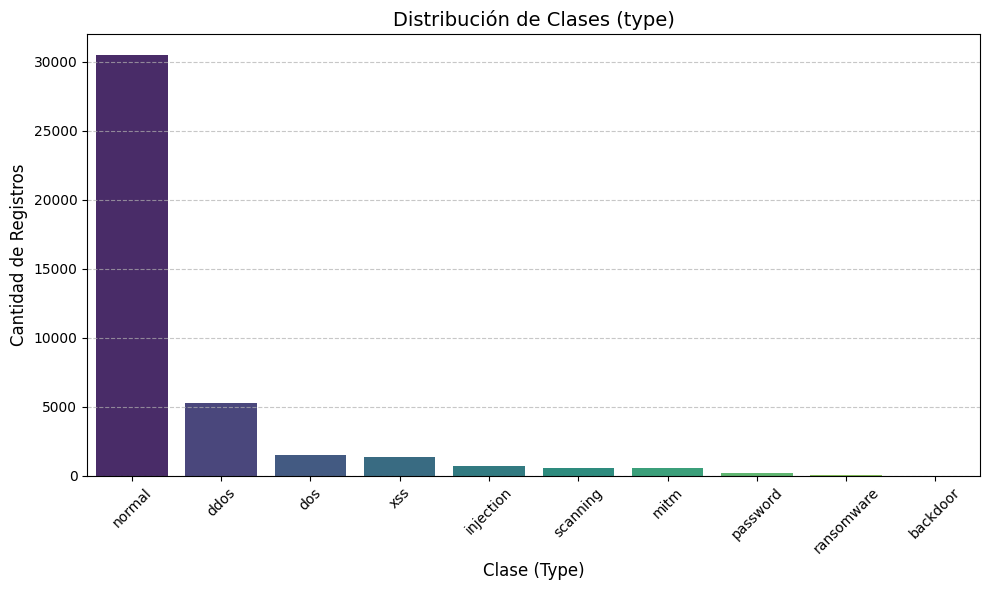

In [ ]:
# Analisis de clases

import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar el DataFrame para registros que dispongan de proto 'udp'
df_udp = df[df['proto'].str.lower() == 'udp']

# Análisis de clases (conteo y porcentaje)
class_counts = df_udp['type'].value_counts()
class_percentages = df_udp['type'].value_counts(normalize=True) * 100
#class_counts = df['type'].value_counts()
#class_percentages = df['type'].value_counts(normalize=True) * 100

# Crear un DataFrame para mostrar los resultados de forma ordenada
analysis_df = pd.DataFrame({
    'Cantidad': class_counts,
    'Porcentaje (%)': class_percentages
})

print("=== Análisis de clases para proto 'udp' ===")
print(analysis_df)

# Generar el gráfico de barras respectivo
plt.figure(figsize=(10, 6))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Distribución de Clases (type)', fontsize=14)
plt.xlabel('Clase (Type)', fontsize=12)
plt.ylabel('Cantidad de Registros', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Escala el dataframe a valores del dataset experimental y variables relacionadas

# Filtrar el DataFrame para quedarnos con proto 'udp' y clases 'normal' y 'ddos'
df_filtered = df[(df['proto'].str.lower() == 'udp') & (df['type'].isin(['normal', 'ddos']))]

# Actualizar la variable df si deseas continuar trabajando sobre el dataset filtrado
df = df_filtered.copy()

# Mostrar el resumen de los datos resultantes
print(f"Dimensiones del DataFrame resultante: {df.shape}")
print("\nDistribución de clases de la columna 'type':")
display(df['type'].value_counts())

Dimensiones del DataFrame resultante: (35722, 44)

Distribución de clases de la columna 'type':


,count
type,
normal,30452
ddos,5270


In [ ]:
# Filtrar las dos clases de interés del DataFrame actual
df_normal = df[df['type'] == 'normal']
df_ddos = df[df['type'] == 'ddos']

# Determinar la cantidad de muestras para mantener la relación 2:1
cantidad_ddos = len(df_ddos)
cantidad_normal_objetivo = cantidad_ddos * 2

# Aplicar submuestreo (under-sampling) a la clase mayoritaria 'normal'
df_normal_sampled = df_normal.sample(n=cantidad_normal_objetivo, random_state=42)

# Concatenar de nuevo los subconjuntos
df_balanced = pd.concat([df_normal_sampled, df_ddos]).sample(frac=1, random_state=42).reset_index(drop=True)

# Reemplazar el DataFrame principal
df = df_balanced.copy()

# Mostrar resultados del balanceo de carga
print("=== Balance de Carga del Dataset (Proporción 2:1) ===")
print(f"Cantidad de registros ddos: {cantidad_ddos}")
print(f"Cantidad de registros normal (submuestreado): {len(df_normal_sampled)}")
print(f"Total de registros tras el balanceo: {df.shape[0]}")
print("\nNueva distribución de clases:")
display(df['type'].value_counts())

=== Balance de Carga del Dataset (Proporción 2:1) ===
Cantidad de registros ddos: 5270
Cantidad de registros normal (submuestreado): 10540
Total de registros tras el balanceo: 15810

Nueva distribución de clases:


,count
type,
normal,10540
ddos,5270


## *Para dataset experimental*



=== Análisis de clases para el Dataset Experimental ===


,Cantidad,Porcentaje (%)
type,,
udp_flood,9485,99.926254
normal,7,0.073746


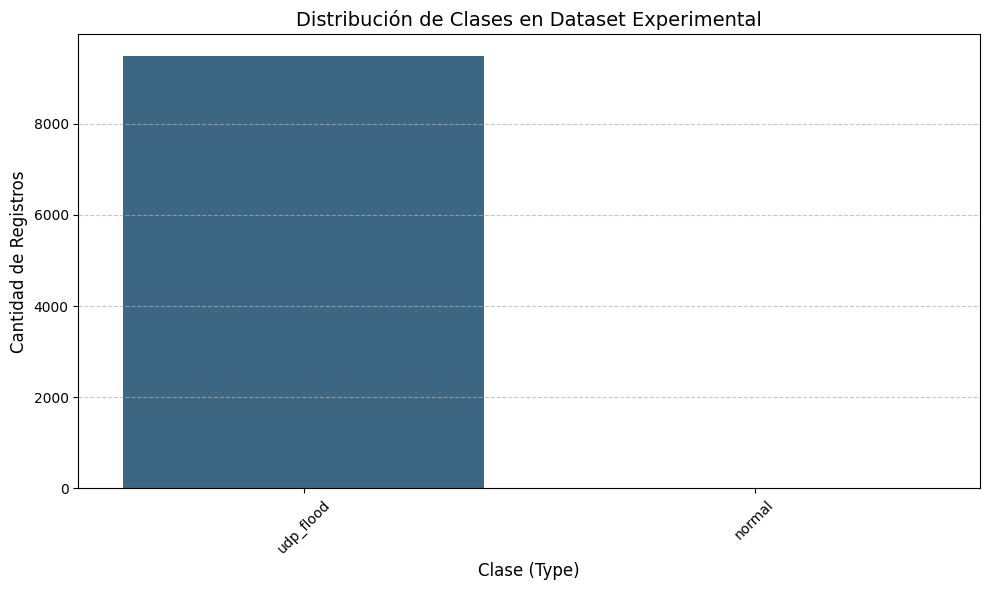

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Análisis de clases para el dataset experimental (df2)
class_counts_exp = df2['type'].value_counts()
class_percentages_exp = df2['type'].value_counts(normalize=True) * 100

# Crear un DataFrame para mostrar los resultados de forma ordenada
analysis_exp_df = pd.DataFrame({
    'Cantidad': class_counts_exp,
    'Porcentaje (%)': class_percentages_exp
})

print("=== Análisis de clases para el Dataset Experimental ===")
display(analysis_exp_df)

# Generar el gráfico de barras respectivo
plt.figure(figsize=(10, 6))
sns.barplot(x=class_counts_exp.index, y=class_counts_exp.values, palette='viridis', hue=class_counts_exp.index, legend=False)
plt.title('Distribución de Clases en Dataset Experimental', fontsize=14)
plt.xlabel('Clase (Type)', fontsize=12)
plt.ylabel('Cantidad de Registros', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Restaurar df2 original desde los datos cargados inicialmente para recuperar el volumen completo
df2 = pd.DataFrame(data2)
df2.drop_duplicates(inplace=True)

# Filtrar las dos clases del dataset experimental original completo
df2_normal = df2[df2['type'] == 'normal']
df2_udp_flood = df2[df2['type'] == 'udp_flood']

cantidad_udp_flood = len(df2_udp_flood)

# Determinar la cantidad de muestras para mantener la relación 4:1 (udp_flood : normal)
# Queremos 1 'normal' por cada 4 'udp_flood'
cantidad_normal_objetivo = int(cantidad_udp_flood / 4)

# Aplicar sobremuestreo (over-sampling) a la clase minoritaria 'normal' con reemplazo
# Usamos los registros existentes sin inventar nuevas direcciones IP
df2_normal_oversampled = df2_normal.sample(n=cantidad_normal_objetivo, replace=True, random_state=42)

# Concatenar los conjuntos
df2_balanced = pd.concat([df2_normal_oversampled, df2_udp_flood]).sample(frac=1, random_state=42).reset_index(drop=True)

# Reemplazar el DataFrame experimental principal
df2 = df2_balanced.copy()

# Mostrar resultados del balanceo de carga
print("=== Balance de Carga del Dataset Experimental Restaurado (Proporción 4:1) ===")
print(f"Cantidad de registros udp_flood (mayoritario): {cantidad_udp_flood}")
print(f"Cantidad de registros normal (sobremuestreado): {len(df2_normal_oversampled)}")
print(f"Total de registros tras el balanceo: {df2.shape[0]}")
print("\nNueva distribución de clases en df2:")
display(df2['type'].value_counts())

=== Balance de Carga del Dataset Experimental Restaurado (Proporción 4:1) ===
Cantidad de registros udp_flood (mayoritario): 9485
Cantidad de registros normal (sobremuestreado): 2371
Total de registros tras el balanceo: 11856

Nueva distribución de clases en df2:


,count
type,
udp_flood,9485
normal,2371


## *Consolidación*

In [ ]:
import pandas as pd

# 1. Asegurar la homologación de etiquetas en df2 (0: normal, 1: udp_flood / ataque)
df2_homologated = df2.copy()
df2_homologated['type'] = df2_homologated['type'].map({'normal': 0, 'udp_flood': 1})

# 2. Mantener únicamente las columnas comunes en ambos datasets para una consolidación limpia
columnas_comunes = ['src_ip', 'dst_ip', 'duration', 'src_bytes', 'dst_bytes', 'src_pkts', 'dst_pkts', 'type']

df_comun = df[columnas_comunes].copy()
df2_comun = df2_homologated[columnas_comunes].copy()

# Añadir una columna origen para identificar la procedencia del dato si es necesario
df_comun['origin'] = 'TON-IoT'
df2_comun['origin'] = 'Experimental'

# 3. Concatenar ambos DataFrames
df_consolidated = pd.concat([df_comun, df2_comun], ignore_index=True)

# Mostrar el resumen de la consolidación
print("=== Consolidación Exitosa ===")
print(f"Registros de TON-IoT (df): {df_comun.shape[0]}")
print(f"Registros del Dataset Experimental (df2): {df2_comun.shape[0]}")
print(f"Dimensiones del Dataset Consolidado Final: {df_consolidated.shape}\n")

print("Distribución final de clases (0: Normal, 1: Ataque / DDoS / UDP Flood):")
display(df_consolidated['type'].value_counts())

print("\nDistribución por origen del dato:")
display(df_consolidated['origin'].value_counts())

# Mostrar las primeras filas como vista previa
display(df_consolidated.head())

=== Consolidación Exitosa ===
Registros de TON-IoT (df): 15810
Registros del Dataset Experimental (df2): 11856
Dimensiones del Dataset Consolidado Final: (27666, 9)

Distribución final de clases (0: Normal, 1: Ataque / DDoS / UDP Flood):


,count
type,
normal,10540
1,9485
ddos,5270
0,2371



Distribución por origen del dato:


,count
origin,
TON-IoT,15810
Experimental,11856


,src_ip,dst_ip,duration,src_bytes,dst_bytes,src_pkts,dst_pkts,type,origin
0,192.168.1.30,192.168.1.1,3.0,52,52,1,1,ddos,TON-IoT
1,192.168.1.195,192.168.1.190,0.0,0,0,1,0,normal,TON-IoT
2,172.17.0.5,192.168.1.190,549.0,0,212,0,2,normal,TON-IoT
3,192.168.1.180,192.168.1.190,605.0,31,106,1,1,normal,TON-IoT
4,192.168.1.31,192.168.1.1,0.0,0,0,0,1,ddos,TON-IoT


# *Transformación de variables*

In [ ]:
display(df_consolidated.head())

,src_ip,dst_ip,duration,src_bytes,dst_bytes,src_pkts,dst_pkts,type,origin
0,192.168.1.30,192.168.1.1,3.0,52,52,1,1,ddos,TON-IoT
1,192.168.1.195,192.168.1.190,0.0,0,0,1,0,normal,TON-IoT
2,172.17.0.5,192.168.1.190,549.0,0,212,0,2,normal,TON-IoT
3,192.168.1.180,192.168.1.190,605.0,31,106,1,1,normal,TON-IoT
4,192.168.1.31,192.168.1.1,0.0,0,0,0,1,ddos,TON-IoT


In [ ]:
import pandas as pd
import numpy as np

# 1. Eliminar la columna 'origin' si existe en df_consolidated
if 'origin' in df_consolidated.columns:
    df_consolidated.drop(columns=['origin'], inplace=True)
    print("La columna 'origin' ha sido eliminada con éxito del dataset consolidado.\n")

# 2. Verificar tipos de datos y necesidades de transformación
print("=== Tipos de Datos en el Dataset Consolidado ===")
print(df_consolidated.dtypes)

# 3. Detectar variables categóricas u objetos que necesiten transformación
categorical_cols = df_consolidated.select_dtypes(include=['object']).columns.tolist()
print(f"\nVariables tipo Objeto/Categóricas detectadas: {categorical_cols}")
if len(categorical_cols) > 0:
    print("Estas variables requerirán un tratamiento (ej. One-Hot Encoding, Label Encoding o exclusión) antes de entrenar nuevos modelos.")

# Mostrar las primeras filas del dataset resultante
print("\nVista previa del dataset consolidado:")
display(df_consolidated.head())

La columna 'origin' ha sido eliminada con éxito del dataset consolidado.

=== Tipos de Datos en el Dataset Consolidado ===
src_ip        object
dst_ip        object
duration     float64
src_bytes      int64
dst_bytes      int64
src_pkts       int64
dst_pkts       int64
type          object
dtype: object

Variables tipo Objeto/Categóricas detectadas: ['src_ip', 'dst_ip', 'type']
Estas variables requerirán un tratamiento (ej. One-Hot Encoding, Label Encoding o exclusión) antes de entrenar nuevos modelos.

Vista previa del dataset consolidado:


,src_ip,dst_ip,duration,src_bytes,dst_bytes,src_pkts,dst_pkts,type
0,192.168.1.30,192.168.1.1,3.0,52,52,1,1,ddos
1,192.168.1.195,192.168.1.190,0.0,0,0,1,0,normal
2,172.17.0.5,192.168.1.190,549.0,0,212,0,2,normal
3,192.168.1.180,192.168.1.190,605.0,31,106,1,1,normal
4,192.168.1.31,192.168.1.1,0.0,0,0,0,1,ddos


In [ ]:
# Mapear las etiquetas de la variable 'type' en el dataset consolidado
# normal -> 0, ddos/udp_flood -> 1.
# Al ya venir algunos valores como 0 o 1, usaremos un mapeo robusto.

df_consolidated['type'] = df_consolidated['type'].replace({
    'normal': 0,
    'ddos': 1,
    'udp_flood': 1
})

print("=== Distribución de la variable 'type' codificada en df_consolidated ===")
print(df_consolidated['type'].value_counts(dropna=False))

print("\nVista previa del dataset consolidado con etiquetas numéricas:")
display(df_consolidated.head())

=== Distribución de la variable 'type' codificada en df_consolidated ===
type
1    14755
0    12911
Name: count, dtype: int64

Vista previa del dataset consolidado con etiquetas numéricas:


/tmp/ipykernel_1260/3357954115.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_consolidated['type'] = df_consolidated['type'].replace({


,src_ip,dst_ip,duration,src_bytes,dst_bytes,src_pkts,dst_pkts,type
0,192.168.1.30,192.168.1.1,3.0,52,52,1,1,1
1,192.168.1.195,192.168.1.190,0.0,0,0,1,0,0
2,172.17.0.5,192.168.1.190,549.0,0,212,0,2,0
3,192.168.1.180,192.168.1.190,605.0,31,106,1,1,0
4,192.168.1.31,192.168.1.1,0.0,0,0,0,1,1


# *Selección de caracteristicas*

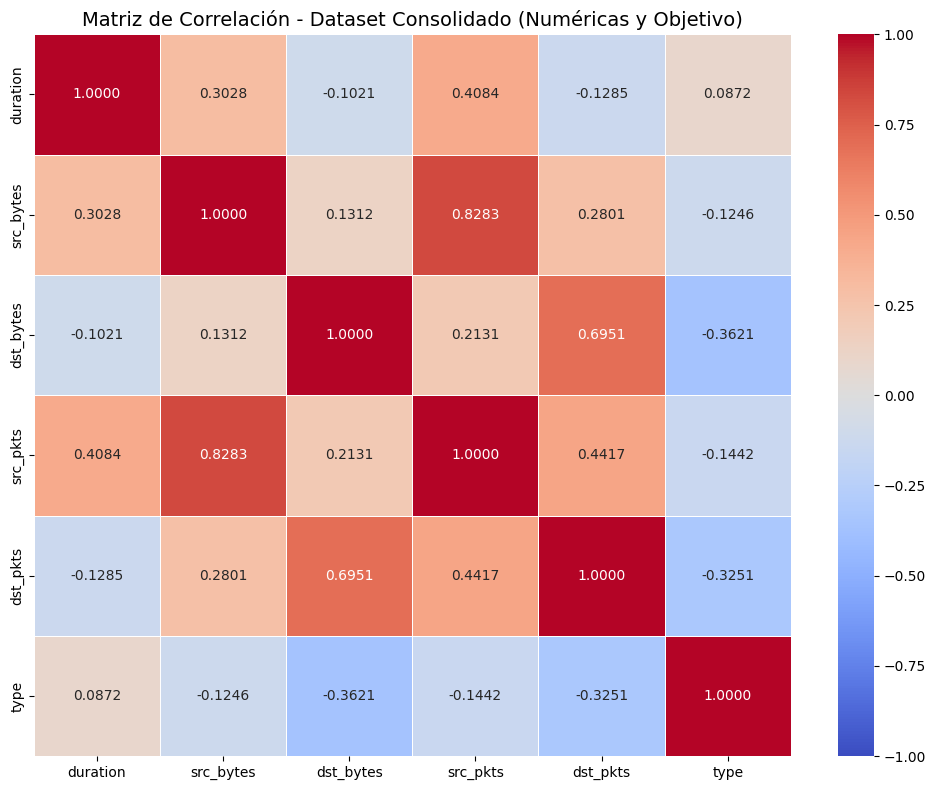

=== Correlación de las características con 'type' en el dataset consolidado ===
type         1.000000
duration     0.087169
src_bytes   -0.124602
src_pkts    -0.144240
dst_pkts    -0.325067
dst_bytes   -0.362107
Name: type, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Asegurar el análisis usando el conjunto consolidado final
df_analysis = df_consolidated.copy()

# Seleccionar las variables numéricas clave para el análisis de correlación
numerical_cols = ['duration', 'src_bytes', 'dst_bytes', 'src_pkts', 'dst_pkts', 'type']

# Forzar tipo numérico por seguridad antes del análisis de correlación
for col in numerical_cols:
    df_analysis[col] = pd.to_numeric(df_analysis[col], errors='coerce')

# Calcular la matriz de correlación
correlation_matrix = df_analysis[numerical_cols].corr()

# Configurar el gráfico
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.4f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title('Matriz de Correlación - Dataset Consolidado (Numéricas y Objetivo)', fontsize=14)
plt.tight_layout()
plt.show()

# Mostrar el resumen de las correlaciones con la variable objetivo
print("=== Correlación de las características con 'type' en el dataset consolidado ===")
print(correlation_matrix['type'].sort_values(ascending=False))


### **2. DIVISION DE DATOS**

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Separar características (X) y etiqueta objetivo (y) usando df_consolidated
# Omitimos 'src_ip' y 'dst_ip' por ser categóricas de alta cardinalidad
features_list = ['duration', 'src_bytes', 'dst_bytes', 'src_pkts', 'dst_pkts']
X = df_consolidated[features_list]
y = df_consolidated['type']

# 2. Primera división: Separar el 15% para el conjunto de Test de forma estratificada
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# 3. Segunda división: Dividir el 85% restante en Entrenamiento (70% del total) y Validación (15% del total)
# El porcentaje de validación relativo sobre el temp es: 15 / 85 ≈ 0.17647
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=(15/85), random_state=42, stratify=y_temp
)

# 4. Mostrar dimensiones de cada partición
print("=== Dimensiones de los Conjuntos de Datos (Dataset Consolidado) ===")
print(f"Entrenamiento (70%): {X_train.shape[0]} muestras")
print(f"Validación    (15%): {X_val.shape[0]} muestras")
print(f"Prueba        (15%): {X_test.shape[0]} muestras")
print(f"Total general:      {X.shape[0]} muestras\n")

# Verificar distribución de clases en cada set
print("=== Distribución de Clases (en %) ===")
print("Entrenamiento:\n", y_train.value_counts(normalize=True) * 100)
print("Validación:\n", y_val.value_counts(normalize=True) * 100)
print("Prueba:\n", y_test.value_counts(normalize=True) * 100)

=== Dimensiones de los Conjuntos de Datos (Dataset Consolidado) ===
Entrenamiento (70%): 19366 muestras
Validación    (15%): 4150 muestras
Prueba        (15%): 4150 muestras
Total general:      27666 muestras

=== Distribución de Clases (en %) ===
Entrenamiento:
 type
1    53.335743
0    46.664257
Name: proportion, dtype: float64
Validación:
 type
1    53.325301
0    46.674699
Name: proportion, dtype: float64
Prueba:
 type
1    53.325301
0    46.674699
Name: proportion, dtype: float64


## **3. MODELOS**

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# ==========================================================
# 0. ESCALADO DE DATOS
# ==========================================================
# Creamos y ajustamos el escalador sobre los conjuntos pre-existentes
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Convertir las etiquetas a numpy arrays por compatibilidad general
y_train_arr = np.array(y_train)
y_val_arr = np.array(y_val)
y_test_arr = np.array(y_test)

# ==========================================================
# 1. MODELO: RANDOM FOREST
# ==========================================================
print("--- Entrenando Random Forest ---")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train_arr)

# Obtener predicciones
test_preds_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
y_test_pred_rf = rf_model.predict(X_test_scaled)

print("Random Forest entrenado con éxito.")


--- Entrenando Random Forest ---
Random Forest entrenado con éxito.


In [ ]:
import xgboost as xgb

# ==========================================================
# 2. MODELO: XGBOOST
# ==========================================================
print("--- Entrenando XGBoost ---")
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

# Entrenamos el modelo usando los datos escalados
xgb_model.fit(
    X_train_scaled,
    y_train_arr,
    eval_set=[(X_val_scaled, y_val_arr)],
    verbose=False
)

# Obtener predicciones para el conjunto de test
test_preds_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]
y_test_pred_xgb = xgb_model.predict(X_test_scaled)

print("XGBoost entrenado con éxito.")

--- Entrenando XGBoost ---


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:52:45] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost entrenado con éxito.


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Input

# ==========================================================
# 3. MODELO: CNN 1D
# ==========================================================
print("--- Preparando datos para CNN 1D ---")
# Reshape para los modelos convolucionales: (muestras, características, 1)
X_train_cnn = np.expand_dims(X_train_scaled, axis=-1)
X_val_cnn = np.expand_dims(X_val_scaled, axis=-1)
X_test_cnn = np.expand_dims(X_test_scaled, axis=-1)

num_features = X_train_scaled.shape[1]

print("--- Entrenando CNN 1D ---")
def create_cnn_1d():
    model = Sequential([
        Input(shape=(num_features, 1)),
        Conv1D(filters=32, kernel_size=2, activation='relu'),
        MaxPooling1D(pool_size=1, padding='same'),
        Dropout(0.2),
        Conv1D(filters=64, kernel_size=2, activation='relu'),
        MaxPooling1D(pool_size=1, padding='same'),
        Dropout(0.3),
        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.4),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

cnn_model = create_cnn_1d()
cnn_model.fit(
    X_train_cnn,
    y_train_arr,
    epochs=15,
    batch_size=64,
    validation_data=(X_val_cnn, y_val_arr),
    verbose=1
)

# Obtener predicciones
test_preds_cnn = cnn_model.predict(X_test_cnn).ravel()
y_test_pred_cnn = (test_preds_cnn > 0.5).astype(int)
print("CNN 1D entrenada con éxito.")

--- Preparando datos para CNN 1D ---
--- Entrenando CNN 1D ---
Epoch 1/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8669 - loss: 0.3487 - val_accuracy: 0.9460 - val_loss: 0.1687
Epoch 2/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9519 - loss: 0.1787 - val_accuracy: 0.9569 - val_loss: 0.1373
Epoch 3/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9558 - loss: 0.1565 - val_accuracy: 0.9525 - val_loss: 0.1490
Epoch 4/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9592 - loss: 0.1468 - val_accuracy: 0.9588 - val_loss: 0.1165
Epoch 5/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9621 - loss: 0.1327 - val_accuracy: 0.9682 - val_loss: 0.1060
Epoch 6/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9663 - loss: 0.1205 - val_accuracy: 0.9696 - val_loss: 0.0978
Epoch 7/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9723 - loss: 0.1051 - val_accuracy: 0.9800 - val_loss: 0.0871
Epoch 8/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 1

In [ ]:
from tensorflow.keras.models import Model
from sklearn.ensemble import RandomForestClassifier
import tensorflow as tf

# ==========================================================
# 4. MODELO HÍBRIDO: CNN 1D + RANDOM FOREST (Stacking)
# ==========================================================
print("--- Extrayendo características de alta representación usando la CNN 1D ---")

# Para evitar el error de 'never been called', usamos la capa de entrada del modelo robustamente
input_layer = cnn_model.layers[0].input if hasattr(cnn_model.layers[0], 'input') else cnn_model.input
feature_extractor = Model(inputs=input_layer, outputs=cnn_model.layers[-4].output)

# Extraemos las características de los conjuntos de datos
X_train_features = feature_extractor.predict(X_train_cnn)
X_val_features = feature_extractor.predict(X_val_cnn)
X_test_features = feature_extractor.predict(X_test_cnn)

print("--- Entrenando Random Forest (Meta-modelo) sobre las características extraídas ---")
cnn_rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
cnn_rf_model.fit(X_train_features, y_train_arr)

# Obtener predicciones para el conjunto de test
test_preds_cnn_rf = cnn_rf_model.predict_proba(X_test_features)[:, 1]
y_test_pred_cnn_rf = cnn_rf_model.predict(X_test_features)

print("Modelo híbrido CNN 1D + Random Forest entrenado con éxito.")

--- Extrayendo características de alta representación usando la CNN 1D ---
606/606 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
--- Entrenando Random Forest (Meta-modelo) sobre las características extraídas ---
Modelo híbrido CNN 1D + Random Forest entrenado con éxito.


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Bidirectional, LSTM, Dense, Dropout, Input

# ==========================================================
# 5. MODELO: CNN 1D + Bi-LSTM
# ==========================================================
print("--- Preparando datos para CNN 1D + Bi-LSTM ---")
# Reshape de los datos escalados a formato 3D (muestras, características, 1)
X_train_lstm = np.expand_dims(X_train_scaled, axis=-1)
X_val_lstm = np.expand_dims(X_val_scaled, axis=-1)
X_test_lstm = np.expand_dims(X_test_scaled, axis=-1)

num_features = X_train_scaled.shape[1]
print(f"Formato de entrada: ({num_features}, 1)")

print("--- Definiendo arquitectura CNN 1D - Bi-LSTM ---")
def create_cnn_bilstm():
    model = Sequential([
        Input(shape=(num_features, 1)),
        # Extracción de características espaciales locales con CNN 1D
        Conv1D(filters=32, kernel_size=2, activation='relu', padding='same'),
        MaxPooling1D(pool_size=1, padding='same'),
        Dropout(0.2),

        # Modelado de secuencias temporales/bidireccionales con Bi-LSTM
        Bidirectional(LSTM(64, return_sequences=False)),
        Dropout(0.3),

        # Capa densa de clasificación
        Dense(32, activation='relu'),
        Dropout(0.4),
        Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# Crear e inspeccionar el modelo
cnn_bilstm_model = create_cnn_bilstm()
cnn_bilstm_model.summary()

print("\n--- Entrenando CNN 1D - Bi-LSTM ---")
history = cnn_bilstm_model.fit(
    X_train_lstm,
    y_train_arr,
    epochs=15,
    batch_size=64,
    validation_data=(X_val_lstm, y_val_arr),
    verbose=1
)

# Obtener predicciones sobre el conjunto de prueba
test_preds_lstm = cnn_bilstm_model.predict(X_test_lstm).ravel()
y_test_pred_lstm = (test_preds_lstm > 0.5).astype(int)

print("Modelo CNN 1D + Bi-LSTM entrenado con éxito.")

--- Preparando datos para CNN 1D + Bi-LSTM ---
Formato de entrada: (5, 1)
--- Definiendo arquitectura CNN 1D - Bi-LSTM ---


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 5, 32)          │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 5, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 5, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        49,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,921 (210.63 KB)

 Trainable params: 53,921 (210.63 KB)

 Non-trainable params: 0 (0.00 B)


--- Entrenando CNN 1D - Bi-LSTM ---
Epoch 1/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.8083 - loss: 0.4180 - val_accuracy: 0.9099 - val_loss: 0.2303
Epoch 2/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9257 - loss: 0.2283 - val_accuracy: 0.9422 - val_loss: 0.1713
Epoch 3/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9394 - loss: 0.1889 - val_accuracy: 0.9441 - val_loss: 0.1501
Epoch 4/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9489 - loss: 0.1617 - val_accuracy: 0.9699 - val_loss: 0.1381
Epoch 5/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9604 - loss: 0.1416 - val_accuracy: 0.9670 - val_loss: 0.1132
Epoch 6/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9662 - loss: 0.1245 - val_accuracy: 0.9660 - val_loss: 0.1117
Epoch 7/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9713 - loss: 0.1160 - val_accuracy: 0.9805 - val_loss: 0.0947
Epoch 8/15
303/303 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accur

## **4. EVALUACION DE METRICAS**

In [ ]:
import time
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score

# Diccionario para almacenar los reportes de rendimiento estructurados por clase
reportes_consolidados = {}

# Definimos las predicciones en probabilidad (necesarias para AUC) y clases para cada modelo
modelos_eval = {
    'Random Forest': {
        'preds_prob': test_preds_rf,
        'preds_class': y_test_pred_rf,
        'es_dl': False
    },
    'XGBoost': {
        'preds_prob': test_preds_xgb,
        'preds_class': y_test_pred_xgb,
        'es_dl': False
    },
    'CNN 1D': {
        'preds_prob': test_preds_cnn,
        'preds_class': y_test_pred_cnn,
        'es_dl': True,
        'x_test': X_test_cnn,
        'model_obj': cnn_model
    },
    'CNN 1D + Random Forest (Híbrido)': {
        'preds_prob': test_preds_cnn_rf,
        'preds_class': y_test_pred_cnn_rf,
        'es_dl': False
    },
    'CNN 1D + Bi-LSTM': {
        'preds_prob': test_preds_lstm,
        'preds_class': y_test_pred_lstm,
        'es_dl': True,
        'x_test': X_test_lstm,
        'model_obj': cnn_bilstm_model
    }
}

# Calcular métricas, latencia de inferencia, AUC y Accuracy para cada uno de los 5 modelos
for nombre, info in modelos_eval.items():
    # 1. Medir Latencia de inferencia en milisegundos por muestra
    num_muestras = len(X_test_scaled)
    if info['es_dl']:
        start_time = time.time()
        _ = info['model_obj'].predict(info['x_test'], verbose=0)
        elapsed = time.time() - start_time
    else:
        start_time = time.time()
        if nombre == 'CNN 1D + Random Forest (Híbrido)':
            # Requiere extracción previa de características para ser justos con su flujo completo
            features_temp = feature_extractor.predict(X_test_cnn, verbose=0)
            _ = cnn_rf_model.predict(features_temp)
        elif nombre == 'Random Forest':
            _ = rf_model.predict(X_test_scaled)
        else:
            _ = xgb_model.predict(X_test_scaled)
        elapsed = time.time() - start_time

    latency_ms_per_sample = (elapsed / num_muestras) * 1000

    # 2. Calcular AUC y Accuracy
    auc = roc_auc_score(y_test_arr, info['preds_prob'])
    acc = accuracy_score(y_test_arr, info['preds_class'])

    # 3. Obtener reporte básico de scikit-learn
    rep = classification_report(y_test_arr, info['preds_class'], output_dict=True)

    # 4. Estructurar la tabla: Columnas como Métricas, Filas como Clases (0 y 1)
    metricas_cols = [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'Soporte (Muestras)',
        'AUC (Área ROC)',
        'Latencia (ms/muestra)'
    ]

    tabla_modelo = pd.DataFrame(columns=metricas_cols, index=['0 (Normal)', '1 (Ataque DDoS)'])

    # Fila 0 (Normal)
    tabla_modelo.loc['0 (Normal)'] = [
        acc,
        rep['0']['precision'],
        rep['0']['recall'],
        rep['0']['f1-score'],
        int(rep['0']['support']),
        auc,
        latency_ms_per_sample
    ]

    # Fila 1 (Ataque DDoS)
    tabla_modelo.loc['1 (Ataque DDoS)'] = [
        acc,
        rep['1']['precision'],
        rep['1']['recall'],
        rep['1']['f1-score'],
        int(rep['1']['support']),
        auc,
        latency_ms_per_sample
    ]

    print("="*85)
    print(f" TABLA DE MÉTRICAS COMPARATIVAS: {nombre.upper()} ")
    print("="*85)
    display(tabla_modelo.round(5))
    print("\n")

 TABLA DE MÉTRICAS COMPARATIVAS: RANDOM FOREST 


,Accuracy,Precision,Recall,F1-Score,Soporte (Muestras),AUC (Área ROC),Latencia (ms/muestra)
0 (Normal),0.990602,0.984184,0.99587,0.989992,1937,0.998857,0.011607
1 (Ataque DDoS),0.990602,0.996347,0.985992,0.991142,2213,0.998857,0.011607




 TABLA DE MÉTRICAS COMPARATIVAS: XGBOOST 


,Accuracy,Precision,Recall,F1-Score,Soporte (Muestras),AUC (Área ROC),Latencia (ms/muestra)
0 (Normal),0.989639,0.984647,0.993289,0.988949,1937,0.999047,0.0029
1 (Ataque DDoS),0.989639,0.99408,0.986444,0.990247,2213,0.999047,0.0029




 TABLA DE MÉTRICAS COMPARATIVAS: CNN 1D 


,Accuracy,Precision,Recall,F1-Score,Soporte (Muestras),AUC (Área ROC),Latencia (ms/muestra)
0 (Normal),0.981446,0.981366,0.978833,0.980098,1937,0.996917,0.068252
1 (Ataque DDoS),0.981446,0.981515,0.983732,0.982622,2213,0.996917,0.068252




 TABLA DE MÉTRICAS COMPARATIVAS: CNN 1D + RANDOM FOREST (HÍBRIDO) 


,Accuracy,Precision,Recall,F1-Score,Soporte (Muestras),AUC (Área ROC),Latencia (ms/muestra)
0 (Normal),0.991325,0.985197,0.996386,0.99076,1937,0.998939,0.079192
1 (Ataque DDoS),0.991325,0.996805,0.986896,0.991826,2213,0.998939,0.079192




 TABLA DE MÉTRICAS COMPARATIVAS: CNN 1D + BI-LSTM 


,Accuracy,Precision,Recall,F1-Score,Soporte (Muestras),AUC (Área ROC),Latencia (ms/muestra)
0 (Normal),0.980964,0.980849,0.978317,0.979581,1937,0.995108,0.098763
1 (Ataque DDoS),0.980964,0.981064,0.983281,0.982171,2213,0.995108,0.098763


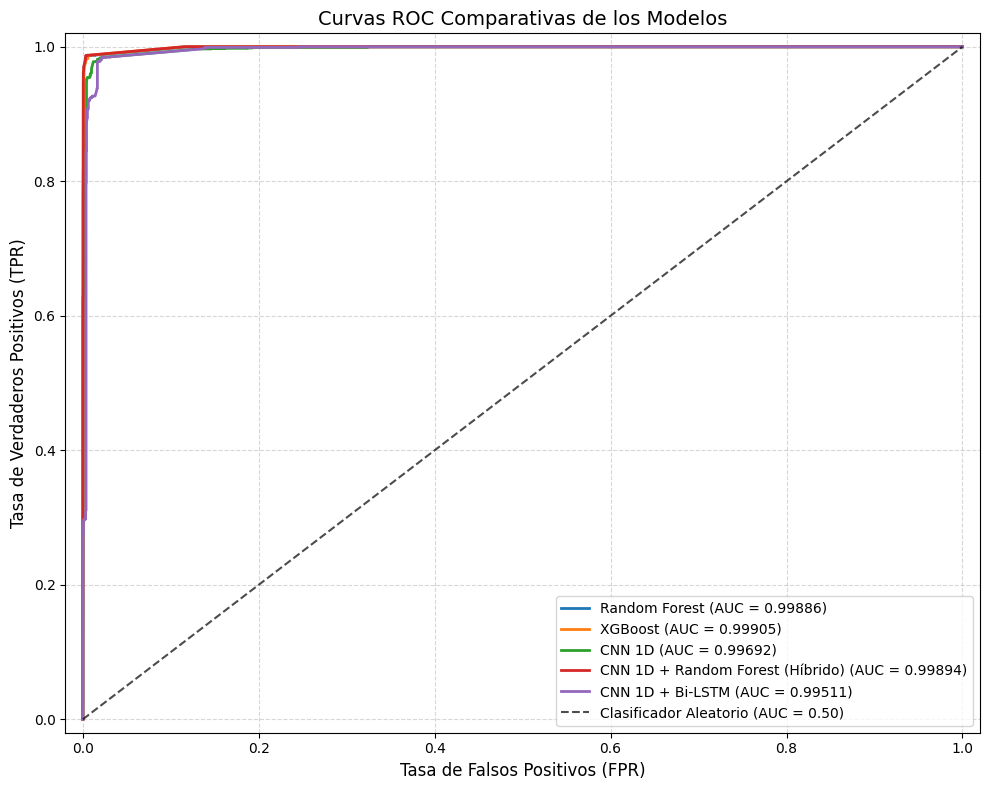

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Configurar el gráfico para las curvas ROC
plt.figure(figsize=(10, 8))

# Graficar la curva para cada modelo utilizando las probabilidades previamente calculadas
for nombre, info in modelos_eval.items():
    fpr, tpr, _ = roc_curve(y_test_arr, info['preds_prob'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc:.5f})', linewidth=2)

# Graficar la línea diagonal de referencia (clasificador aleatorio)
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio (AUC = 0.50)', alpha=0.7)

# Ajustes estéticos de la gráfica
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=12)
plt.title('Curvas ROC Comparativas de los Modelos', fontsize=14)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

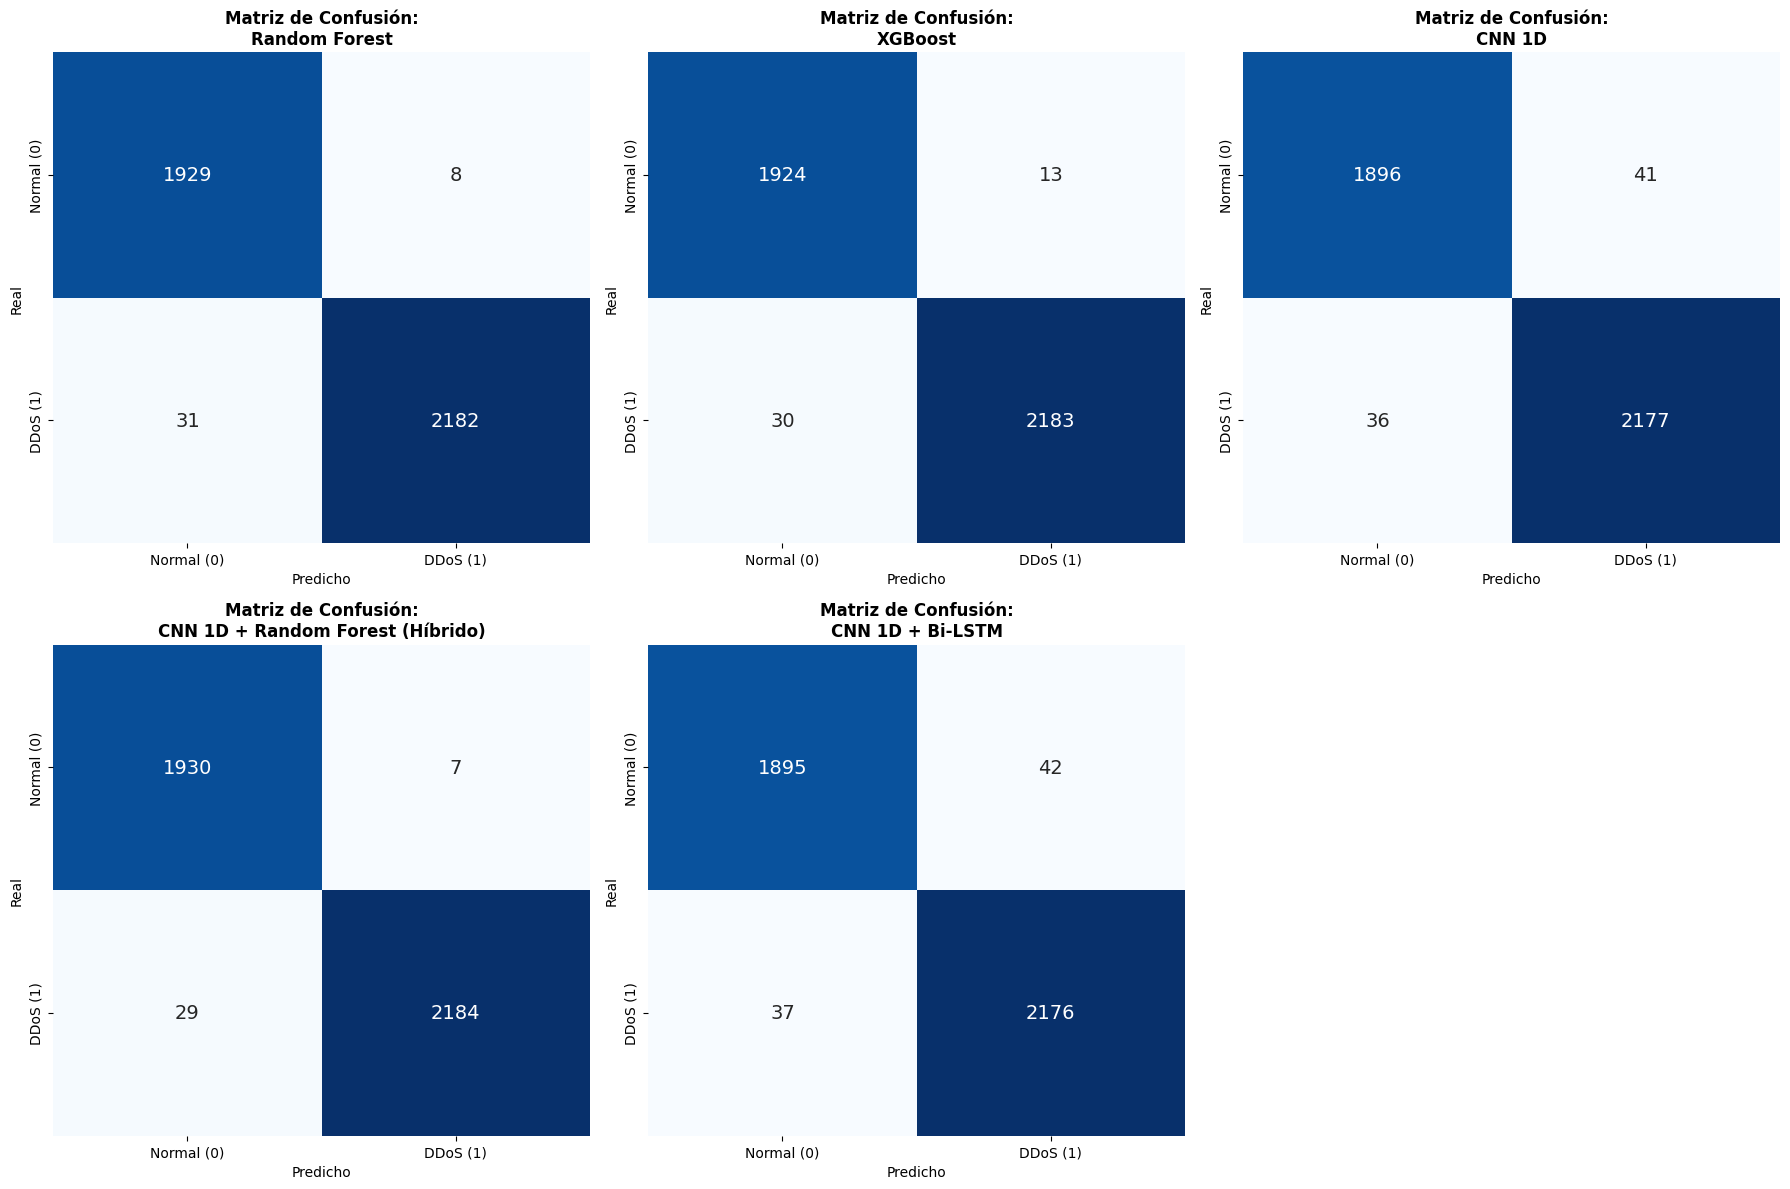

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Definir el nombre de las clases
class_names = ['Normal (0)', 'DDoS (1)']

# Configurar la cuadrícula de gráficos (2 filas, 3 columnas para acomodar los 5 modelos)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

# Iterar sobre cada modelo de nuestro diccionario de evaluación
for idx, (nombre, info) in enumerate(modelos_eval.items()):
    # Calcular la matriz de confusión
    cm = confusion_matrix(y_test_arr, info['preds_class'])

    # Graficar usando seaborn en el subgráfico correspondiente
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[idx],
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=False,
        annot_kws={'size': 14}
    )

    axes[idx].set_title(f'Matriz de Confusión:\n{nombre}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicho', fontsize=10)
    axes[idx].set_ylabel('Real', fontsize=10)

# Ocultar el último subgráfico vacío (ya que son 5 modelos y 6 espacios)
axes[-1].axis('off')

plt.tight_layout()
plt.show()